# Laboratorio: Algoritmo di discesa del gradiente

### Applicare l'algoritmo di discesa del gradiente alla seguente funzione.
$$
f : \mathbb{R}^2 \rightarrow \mathbb{R}
$$
$$
f(x, y) = x \log(y)
$$

Ovvero, usare `numpy` e `matplotlib` per:
- definire la funzione
- visualizzare la funzione
    - prima definire una meshgrid (visualizzare la meshgrid con plot scatter)
    - poi visualizzare la superficie
    - infine, visualizzare le sue curve di livello
- calcolare il gradiente della funzione
- definire una strategia di arresto
- implementare l'algoritmo di discesa del gradiente
- applicare l'algoritmo alla funzione f
- visualizzare il percorso individuato dall'algoritmo
    - visualizzazione sulla superficie
    - visualizzazione "dall'alto"

In [110]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# definizione della funzione da minimizzare

def f(x):
    return x[0] * np.log(x[1])

In [111]:
# creazione linspace e meshgrid
lin_x = np.linspace(0, 6)
lin_y = np.linspace(1, 3)

print(lin_x.shape, lin_y.shape)

xy = np.meshgrid(lin_x, lin_y)

print(xy[0].shape, xy[1].shape)


(50,) (50,)
(50, 50) (50, 50)


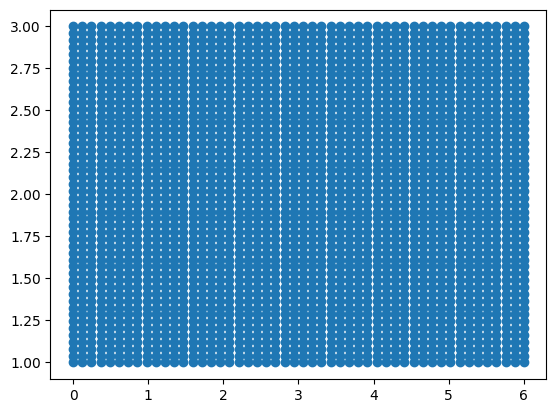

In [112]:
# plot della meshgrid

plt.scatter(*xy)
plt.show()

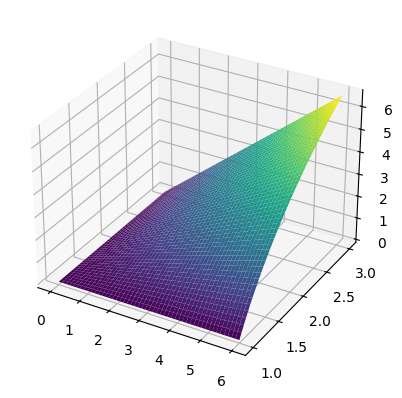

In [113]:
# plot della funzione

ax = plt.axes(projection="3d")

ax.plot_surface(*xy, f(xy), cmap=cm.viridis)

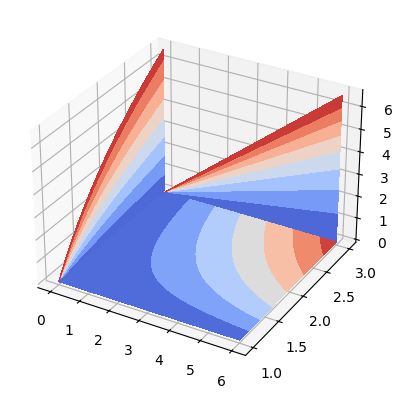

In [114]:
# plot delle curve di livello della funzione
axCL = plt.axes(projection="3d")

axCL.contourf(*xy, f(xy), zdir="z", offset=0, cmap="coolwarm")
axCL.contourf(*xy, f(xy), zdir="x", offset=0, cmap="coolwarm")
axCL.contourf(*xy, f(xy), zdir="y", offset=3, cmap="coolwarm")

Gradiente di $f$:
$$
\frac{\partial f}{\partial x} = \log(y), \qquad \frac{\partial f}{\partial y} = \frac{x}{y}
$$

In [115]:
# funzione che ritorna il gradiente della funzione da minimizzare

def f_gradient(x):
    return np.array([np.log(x[1]), (x[0] / x[1])])

Per sapere qual è un punto stazionario a cui puntare con il metodo di discesa, dobbiamo vedere quando il gradiente si annulla.

Questo succede per $x = 0$ e $y = 1$.

La strategia di terminazione diventa quindi:
$$
||\nabla f|| < \varepsilon
$$

oppure:
$$
|| (x_k, y_k) - (0, 1) || < \varepsilon
$$

In [116]:
# algoritmo di discesa del gradiente
def gradient_descent(x_0, eta, iter, epsilon):
    x = [x_0]
    

    for _ in range(iter - 1):
        # x[-1], vuol dire ultimo elemento della lista
        grad = f_gradient(x[-1])

        if np.linalg.norm(grad) < epsilon:
            break

        x_k = x[-1] - eta * grad

        x.append(x_k)


    return np.array(x).transpose()

(2, 1)
[[1]
 [5]]


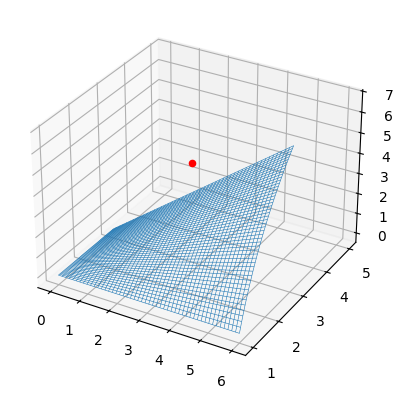

In [124]:
# visualizzazione del percorso di discesa del gradiente

N_ITER = 1
epsilon = 0.001
eta = 0.1
x_0 = np.array([1, 5])
#print(x_0)

min_x = gradient_descent(x_0, eta, N_ITER, epsilon)

print(min_x.shape)
print(min_x)
ax2 = plt.axes(projection="3d")

ax2.plot_wireframe(*xy, f(xy), linewidth=0.4)
ax2.scatter(*min_x, f(min_x), c="r")

plt.show()

### Applicare poi l'algoritmo alle seguenti funzioni.


#### Loss $L_1$, detta "geometria del taxi".
$$
L_1 : \mathbb{R}^{2N} \rightarrow \mathbb{R}
$$

$$
L_1(\underline{x}, \underline{y}) = \frac{1}{N} \sum_{i = 1}^N {| x_i - y_i |}
$$
dove $\underline{x} \in \mathbb{R}^N$ e $\underline{y} \in \mathbb{R}^N$.


*Suggerimento:* per visualizzare la funzione, prendere ad esempio $N = 1$.

In [ ]:
# definizione funzione da minimizzare e plot


In [ ]:
# definizione gradiente, algoritmo di discesa del gradiente e visualizzazione percorso

In [ ]:
# usare altre strategie di terminazione dell'algoritmo di discesa del gradiente

#### Loss $L_2$, detta MSE (Mean Squared Error).
$$
L_2 : \mathbb{R}^{2N} \rightarrow \mathbb{R}
$$

$$
L_2(\underline{x}, \underline{y}) = \frac{1}{2N} \sum_{i = 1}^N {| x_i - y_i |}^2
$$
dove $\underline{x} \in \mathbb{R}^N$ e $\underline{y} \in \mathbb{R}^N$.

In [ ]:
# definizione della funzione da minimizzare, plot e visualizzazione percorso di discesa del gradiente

#### Cross-Entropy Loss.
$$
CE : \mathbb{R}^{2N} \rightarrow \mathbb{R}
$$

$$
CE(\underline{x}, \underline{y}) = \sum_{i = 1}^N x_i \log(y_i) 
$$

dove $\underline{x} \in \mathbb{R}^N$ e $\underline{y} \in \mathbb{R}^N$.

In [ ]:
# definizione della funzione da minimizzare, algoritmo di discesa del gradiente